# ISO 20414:2020 — Test 9: Dynamic Availability of Exit
A 10 m x 15 m room has two exits available on the 15 m walls of the room (ISO 20414:2020 Table 10). They are equally distant from the occupant spanned at the 10 m long wall at the end of the room. Exit 1 becomes unavailable after 1 s of simulation time. Expected result is that Exit 1 is not used by the occupant.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 17:30 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario, ScenarioRunner
from jupedsim_scenarios.direct_steering_runtime import pick_stage_target

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load the Scenario 

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Iso-09-dynamic-exits.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
print(scenario.summary())

Scenario: scenario_files/Iso-09-dynamic-exits.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         2
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~1
    jps-distributions_0: 1 agents


## Run the Scenario - Exit 1 Closes after 1 s

In [6]:
EXIT_1 = "jps-exits_0"
EXIT_2 = "jps-exits_1"
def redirect_agent(runner, agent_id, exit_key):
    """Change the agent's current destination."""
    state = runner._agent_wait_info[agent_id]
    exit_config = state["stage_configs"][exit_key]

    state["current_target_stage"] = exit_key
    state["target"] = pick_stage_target(state, exit_config)
    state["target_assigned"] = False
    state["state"] = "to_target"
    state["inside_since"] = None
    state["wait_until"] = None

with ScenarioRunner(
    scenario,
    seed=42,
    every_nth_frame=1,
) as runner:
    agent = next(iter(runner.agents()))
    agent_id = agent.id

    # Both exits are initially available, but the tested occupant starts
    # by targeting Exit 1.
    redirect_agent(runner, agent_id, EXIT_1)

    # At t = 1 s, Exit 1 becomes unavailable.
    runner.run_until(1.0)
    redirect_agent(runner, agent_id, EXIT_2)

    # Continue until the occupant evacuates.
    runner.run_until()
    result = runner.result()

df = result.trajectory_dataframe()

print(f"Evacuation time: {result.evacuation_time:.2f} s")
print(f"Agents remaining: {result.agents_remaining}")

Evacuation time: 13.78 s
Agents remaining: 0


In [7]:
exit_polygons = {
    exit_id: Polygon(exit_data["coordinates"])
    for exit_id, exit_data in scenario.raw["exits"].items()
}

last_position = df.sort_values("frame").iloc[-1]
last_point = Point(last_position["x"], last_position["y"])

actual_exit = min(
    exit_polygons,
    key=lambda exit_id: exit_polygons[exit_id].distance(last_point),
)

exit_names = {
    EXIT_1: "Exit 1",
    EXIT_2: "Exit 2",
}

print(f"Exit used: {exit_names[actual_exit]}")

Exit used: Exit 2


## Scenario figure

Room geometry from the loaded scenario: the occupant starts at the far wall, both exits equally distant.

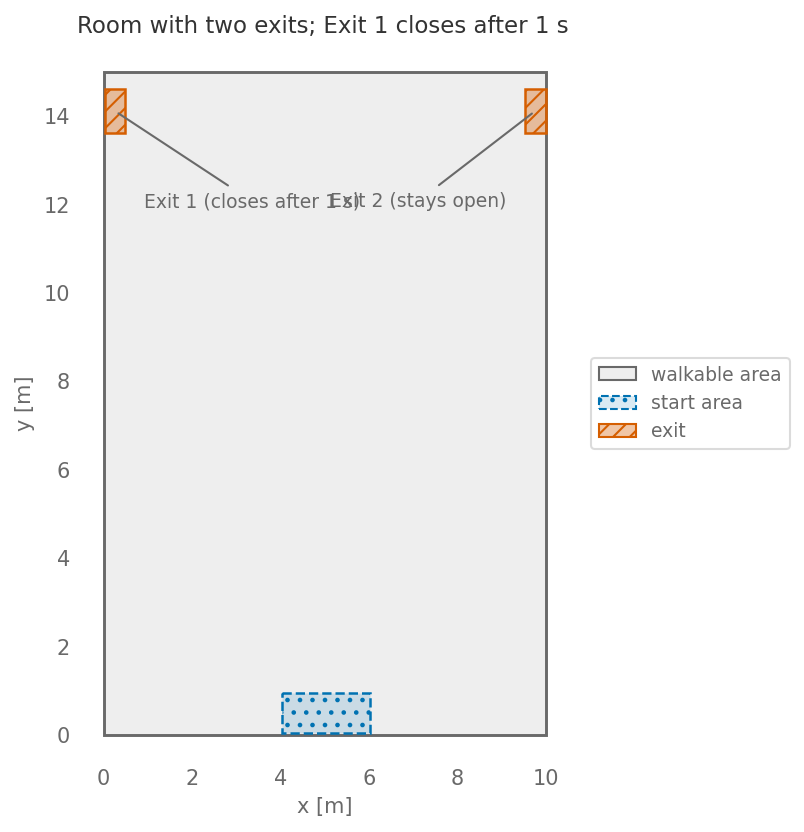

In [8]:
# Scenario geometry from the loaded ZIP.
from shapely.geometry import Polygon
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(5.2, 6.2))
    handles = vv_draw_scenario(ax, scenario)
    for ex_id, ex in scenario.exits.items():
        c = Polygon(ex["coordinates"]).centroid
        label = "Exit 1 (closes after 1 s)" if ex_id == EXIT_1 else "Exit 2 (stays open)"
        left = ex_id == EXIT_1
        ax.annotate(label, xy=(c.x, c.y), xytext=(14 if left else -14, -46), textcoords="offset points",
                    ha="left" if left else "right", color="dimgrey", fontsize=9,
                    arrowprops={"arrowstyle": "-", "color": "dimgrey"})
    ax.set_title("Room with two exits; Exit 1 closes after 1 s", loc="left")
    ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5))
    plt.show()

## Plot Trajectory

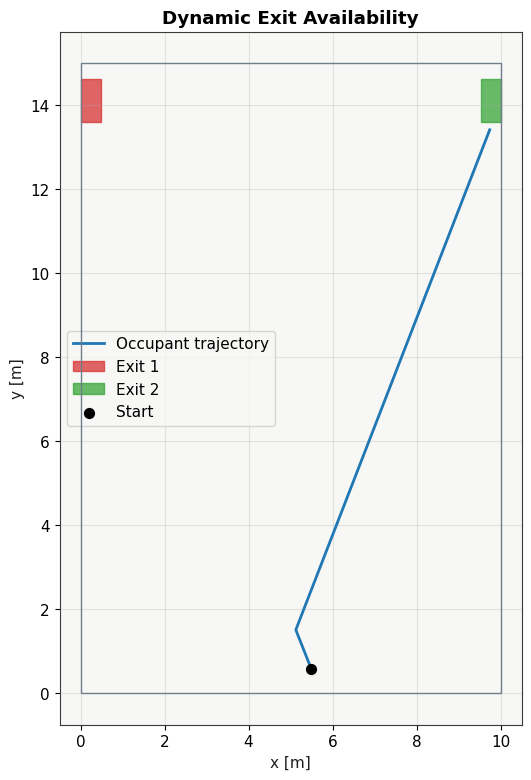

In [9]:
walkable_area = pedpy.WalkableArea(scenario.walkable_polygon)
fig, ax = plt.subplots(figsize=(7, 9))
pedpy.plot_walkable_area(walkable_area=walkable_area, axes=ax)
ax.plot(
    df["x"],
    df["y"],
    color="tab:blue",
    linewidth=2,
    label="Occupant trajectory",
)
for exit_id, polygon in exit_polygons.items():
    x, y = polygon.exterior.xy
    color = "tab:red" if exit_id == EXIT_1 else "tab:green"

    ax.fill(
        x,
        y,
        color=color,
        alpha=0.7,
        label=exit_names[exit_id],
    )
ax.scatter(
    df.iloc[0]["x"],
    df.iloc[0]["y"],
    color="black",
    marker="o",
    s=50,
    label="Start",
    zorder=5,
)

ax.set_title("Dynamic Exit Availability")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.show()

## Acceptance

In [10]:
assert actual_exit == EXIT_2, (
    f"Expected Exit 2 to be used after Exit 1 became unavailable, "
    f"but {exit_names[actual_exit]} was used."
)
result.cleanup();